# Tugas 2 — Deteksi Transaksi *Fraud* (Klasifikasi Biner)

Notebook ini menjalankan pipeline Tugas 2 langkah demi langkah dengan kode yang sama seperti
`python kode/run_all.py --stages klasifikasi`. Setiap butir menjalankan modulnya di
`kode/src/klasifikasi/`, lalu menampilkan ringkasan angka dari `kode/results/` dan grafik dari
`kode/figures/`.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 2a | Audit label dan fitur serta pengukuran dampaknya | `audit.py`, `audit_dampak.py` | Firdaus Arif Ramadhani |
| 2b | Validasi berbasis waktu yang tahan *right-censoring* | `validation.py` | Firdaus Arif Ramadhani |
| 2c | Fitur perilaku kausal pengguna dan *merchant* | `features.py` | Rainaldi Pakpahan |
| 2d | Penanganan *class imbalance* dan perbandingan model | `models.py` | Rainaldi Pakpahan |
| 2e | Pergeseran pola *fraud* dan adaptasi model | `shift.py` | Rainaldi Pakpahan |
| 2f | Kalibrasi probabilitas dan aturan keputusan berbasis biaya | `calibration.py` | Rainaldi Pakpahan |
| 2g | Analisis *error*, SHAP, dan `prediksi_klasifikasi.csv` | `analysis.py` | Rainaldi Pakpahan |

Metrik penilaian: PR-AUC dari `prob` dan biaya total = jumlah nominal *fraud* yang lolos + Rp25.000 ×
jumlah transaksi yang ditandai. Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan dua pembantu: `baca_hasil()` untuk membaca JSON hasil
dan `tampilkan_gambar()` untuk menampilkan grafik. Data dibaca dari folder `data/` di *root* repositori
(atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama: str, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    gambar = PILImage.open(FIGURES_DIR / nama)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 2a. Audit Label dan Fitur

*Penanggung jawab: Firdaus Arif Ramadhani*

Pemeriksaan yang dijalankan `audit.py`:

- **Skema, waktu, dan ID:** dimensi, duplikat, irisan *train*–*test*, urutan baris, keacakan ID.
- **Jeda label (*right-censoring*):** *fraud* baru terkonfirmasi beberapa hari setelah transaksi,
  sehingga label Agustus 2025 belum lengkap pada tanggal penarikan data.
- ***Leakage*:** `flag_review_manual` terjadi sesudah transaksi sehingga tidak boleh dipakai.
- **Kualitas data:** *missing* terstruktur, `umur_merchant_hari < 0`, `persen_saldo` yang terpotong di 50,
  entitas *unseen*.
- ***Screening* `v01`–`v50`:** memisahkan fitur anonim yang bersinyal dari yang *noise*.
- **Pergeseran pola:** gelombang *fraud* QRIS mulai Agustus 2025.
- **Dampak:** empat eksperimen mengukur efek setiap temuan pada split kronologis yang labelnya matang.

In [2]:
%run ../src/klasifikasi/audit.py --save-json

[START] Muat dataset klasifikasi


[DONE]  Muat dataset klasifikasi (1.24s)
[START] 2a.1 Skema & duplikat


  Train=[403077, 85], Test=[106674, 84], dup_id=0
[DONE]  2a.1 Skema & duplikat (0.80s)
[START] 2a.2 Rentang waktu & urutan
  Train terurut=False, Test terurut=False
[DONE]  2a.2 Rentang waktu & urutan (0.08s)
[START] 2a.3 Keacakan ID


  Spearman(id_transaksi, waktu)=0.00034
[DONE]  2a.3 Keacakan ID (0.38s)
[START] 2a.4 Label & kurva delay konfirmasi


  Laju matang Jan–Jul=0.679%, Agt=0.463%, 29–31 Agt fraud=0/4780
[DONE]  2a.4 Label & kurva delay konfirmasi (1.06s)
[START] 2a.5 Audit forensik leakage flag_review_manual


  Review rate train=1.71% (non-fraud=1.20%), test=1.23%
[DONE]  2a.5 Audit forensik leakage flag_review_manual (0.66s)
[START] 2a.6 Kualitas fitur, missing, anomali, & unseen


  umur_merchant<0: n_tr=955 (fraud=20.31%), n_te=20
[DONE]  2a.6 Kualitas fitur, missing, anomali, & unseen (2.40s)
[START] 2a.7 Screening 50 fitur anonim v01–v50


  8 sinyal v=['v03', 'v11', 'v19', 'v26', 'v29', 'v38', 'v42', 'v47']; v15 drift KS=0.502, AUC=0.503
[DONE]  2a.7 Screening 50 fitur anonim v01–v50 (9.61s)
[START] 2a.8 Pergeseran pola fraud & arketipe modus


  QRIS fraud Jan–Jul=0.119% -> Agt=0.789%; QRIS bulat 100rb di Agt fraud=79.3%, di test=461
[DONE]  2a.8 Pergeseran pola fraud & arketipe modus (0.59s)
[START] 2a.9 Eksperimen dampak kuantitatif (4 temuan)


  PR-AUC bocor CV=0.9017 -> simulasi uji=0.6889 vs jujur=0.7656
[DONE]  2a.9 Eksperimen dampak kuantitatif (4 temuan) (67.47s)
[SAVED] task2_audit.json


In [3]:
audit = baca_hasil("task2_audit.json")
label = audit["label_delay"]
display(Markdown("**Laju fraud (%) menurut kematangan label**"))
display(pd.Series({
    "Seluruh train": label["laju_fraud_total_pct"],
    "Jan–Jul (label matang)": label["laju_fraud_matang_pct"],
    "Agustus (tersensor)": label["laju_fraud_agustus_pct"],
}, name="laju_fraud_pct").to_frame())

kolom = ["pr_auc", "roc_auc", "ratio_pred_to_obs", "flag_rate_pct", "total_cost_idr"]
baris = {}
for eksperimen, isi in audit["dampak"].items():
    if not isinstance(isi, dict) or eksperimen == "split_info":
        continue
    for varian, metrik in isi.items():
        if isinstance(metrik, dict) and "pr_auc" in metrik:
            baris[(eksperimen, varian)] = {k: metrik.get(k) for k in kolom}
display(Markdown("**Eksperimen dampak (split kronologis matang)**"))
display(pd.DataFrame.from_dict(baris, orient="index"))

**Laju fraud (%) menurut kematangan label**

,laju_fraud_pct
Seluruh train,0.6505
Jan–Jul (label matang),0.6788
Agustus (tersensor),0.4631


**Eksperimen dampak (split kronologis matang)**

pr_auc  roc_auc  ratio_pred_to_obs  flag_rate_pct  total_cost_idr
indikator_kualitas    matang_jun_jul_dasar             0.7656   0.9873             0.9466         1.0953      7.4257e+07
                      matang_jun_jul_dengan_flag       0.7645   0.9877             0.9456         1.1323      7.4609e+07
                      qris_shift_agt11_21_dasar        0.5227   0.9865             0.7536         1.7300      8.7048e+06
                      qris_shift_agt11_21_dengan_flag  0.5733   0.9907             0.9438         1.8275      4.0054e+06
label_delay_censoring val_agt_akhir_15_31              0.1247   0.9254             2.2541         1.0910      3.8168e+07
                      val_agt_akhir_non_qris           0.1786   0.9852             3.7430         1.2207      8.3786e+06
                      val_agt_penuh_tersensor          0.2747   0.9251             1.3453         1.2041      1.1865e+08
                      val_jul_matang                   0.7830   0.9870             0.9977         1.2497      3.6901e+07
leakage_review_manual dengan_review_cv_naif            0.9017   0.9956             0.9615         0.8023      3.6775e+07
                      dengan_review_simulasi_uji       0.6889   0.9825             0.6850         0.6806      9.7322e+07
                      jujur_tanpa_review               0.7656   0.9873             0.9466         1.0953      7.4257e+07
seleksi_fitur_v       bernama_plus_8_v_sinyal          0.7656   0.9873             0.9466         1.0953      7.4257e+07
                      hanya_bernama_tanpa_v            0.7607   0.9862             0.9713         1.2414      7.7586e+07
                      semua_50_v                       0.7566   0.9856             0.9185         1.0671      7.6476e+07

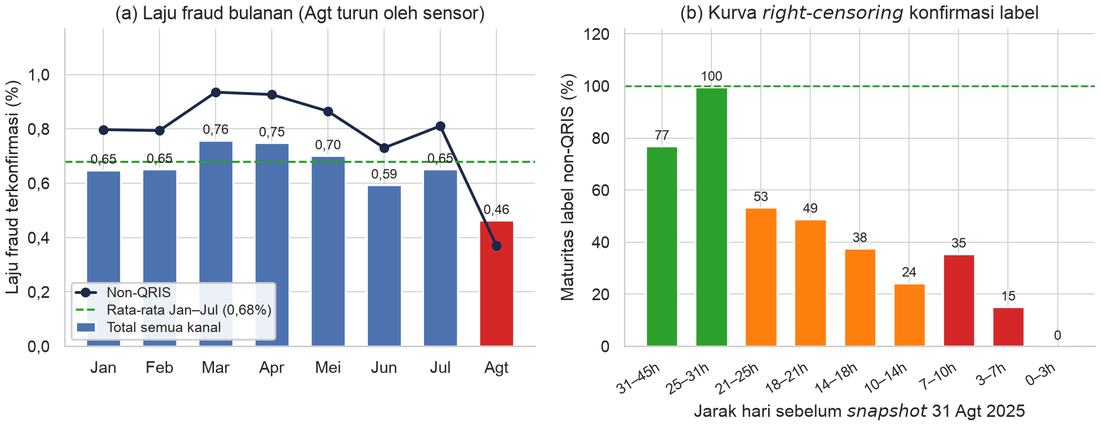

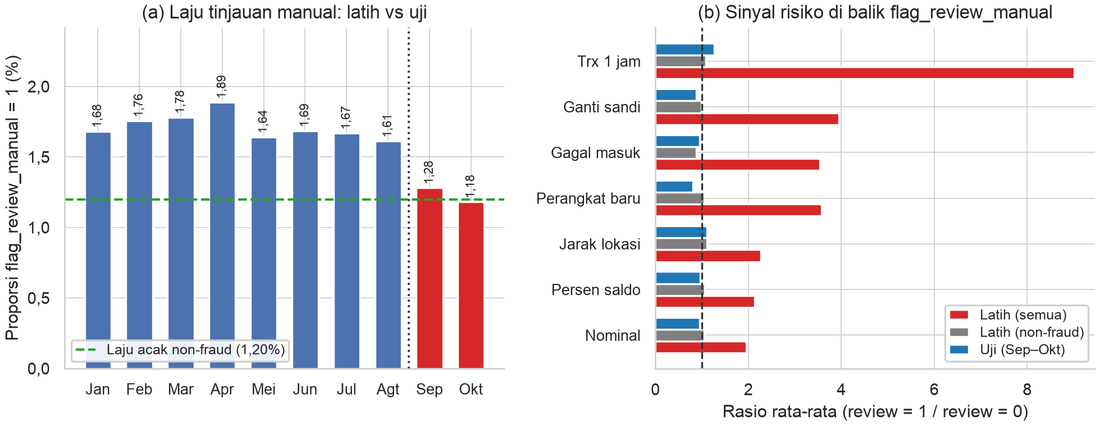

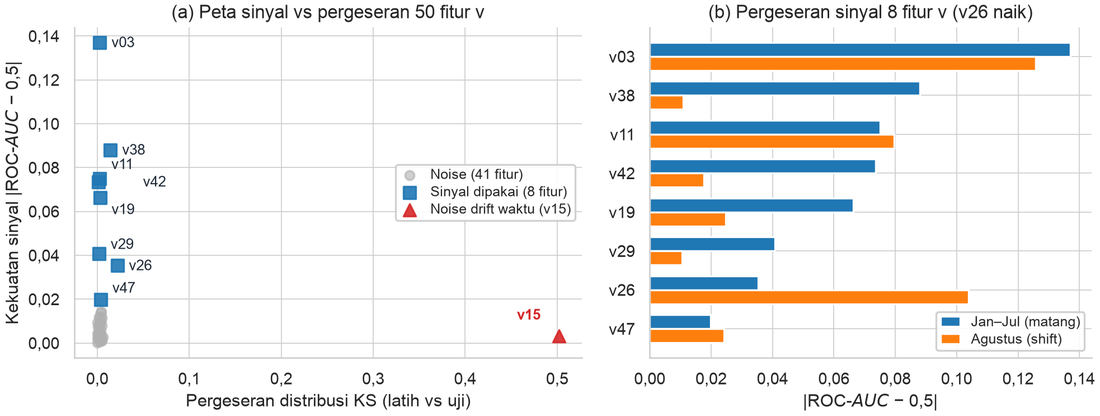

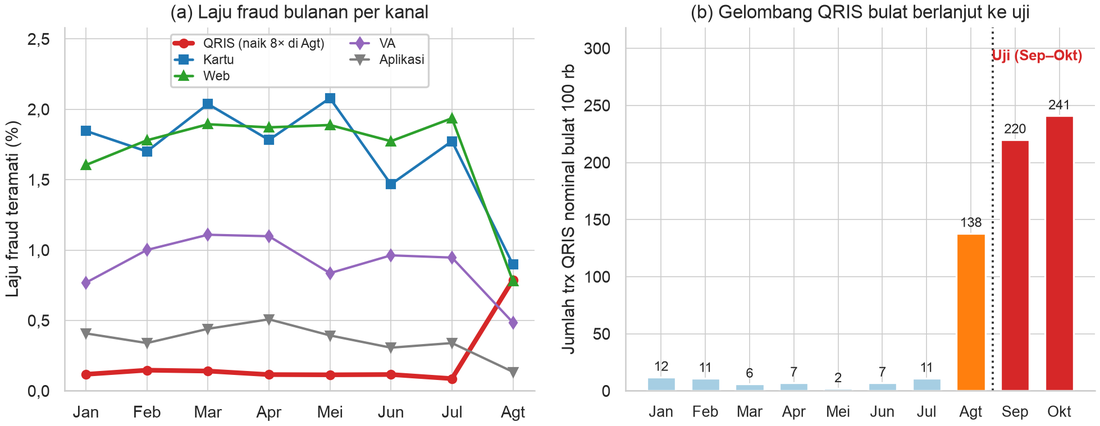

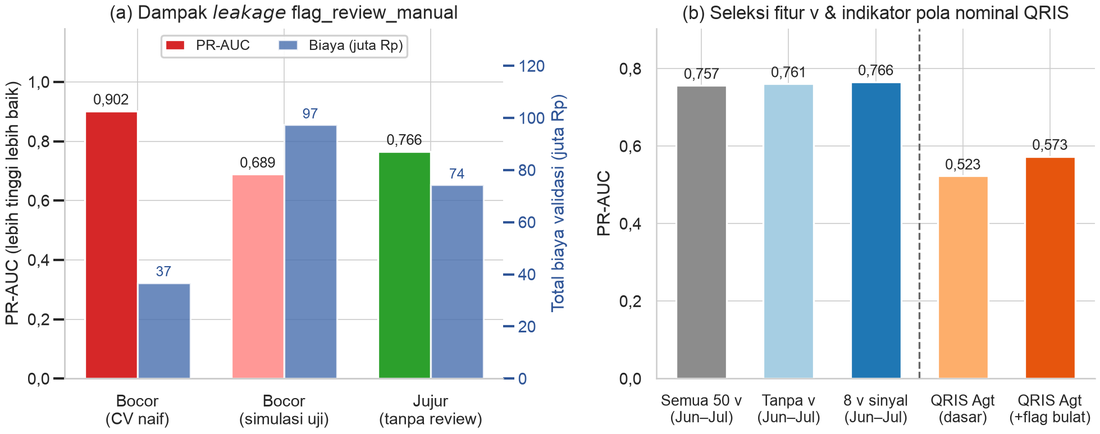

In [4]:
for nama in (
    "task2_2a1_label_delay.png",
    "task2_2a2_leakage_review.png",
    "task2_2a3_v_screening.png",
    "task2_2a4_pattern_shift.png",
    "task2_2a5_dampak_audit.png",
):
    tampilkan_gambar(nama)

## 2b. Validasi Berbasis Waktu yang Tahan *Right-Censoring*

*Penanggung jawab: Firdaus Arif Ramadhani*

Skema resmi: *expanding-window time CV* 3 *fold* (Mei, Juni, Juli 2025). Setiap *fold* validasi
berjarak ≥ 31 hari sebelum *snapshot* 31 Agustus 2025 sehingga labelnya matang. Skema ini
dibandingkan dengan:

- *stratified random* 5-*fold* CV pada Januari–Juli (optimisme semu karena waktu, pengguna, dan
  *merchant* yang sama tercampur);
- validasi naif pada Agustus yang labelnya belum lengkap.

In [5]:
%run ../src/klasifikasi/validation.py

[START] Muat & siapkan data latih klasifikasi


[DONE]  Muat & siapkan data latih klasifikasi (1.29s)
[START] 2b.1 Expanding-Window Time CV Matang (3 Fold: Mei, Jun, Jul)


  Time CV Matang: PR-AUC=0.7767 ± 0.0274, Biaya/10k=7,208,807 Rp, rasio=0.92
[DONE]  2b.1 Expanding-Window Time CV Matang (3 Fold: Mei, Jun, Jul) (17.87s)
[START] 2b.2 Pembanding Stratified Random 5-Fold CV (Jan–Jul Matang)


  Random 5-Fold : PR-AUC=0.8132 ± 0.0191, Biaya/10k=7,633,963 Rp
[DONE]  2b.2 Pembanding Stratified Random 5-Fold CV (Jan–Jul Matang) (30.66s)
[START] 2b.3 Evaluasi Naif pada Agustus Tersensor (Agt 1–31 & 15–31)


  Agt 1–7 non-QRIS: PR-AUC=0.6805, rasio=1.12
  Agt 1–31 naif   : PR-AUC=0.2931, rasio=1.34
  Agt 15–31 berat : PR-AUC=0.1341, rasio=2.25
[DONE]  2b.3 Evaluasi Naif pada Agustus Tersensor (Agt 1–31 & 15–31) (6.67s)
[SAVED] task2_validation.json


**Time CV matang vs random CV**

,mean_pr_auc,std_pr_auc,mean_roc_auc,std_roc_auc,mean_cost_per_10k_tx_idr,mean_ratio_pred_to_obs
Time CV matang (3 fold),0.7767,0.0274,0.9863,0.0020,7.2088e+06,0.9191
Stratified random 5-fold,0.8132,0.0191,0.9880,0.0006,7.6340e+06,0.9271


**Evaluasi pada Agustus yang tersensor**

,n_val,n_val_fraud,obs_rate_pct,pr_auc,roc_auc,ratio_pred_to_obs
agt_1_7_matang,11785,110,0.9334,0.5074,0.9319,0.7981
agt_1_7_non_qris,9197,76,0.8264,0.6805,0.9894,1.1235
agt_akhir_15_31_berat,28415,70,0.2463,0.1341,0.9303,2.2543
agt_penuh_1_31_naif,52904,245,0.4631,0.2931,0.9289,1.3360


,nilai
optimisme_random_vs_time_pct,4.7102
optimisme_random_vs_time_pr_auc,0.0366
penurunan_pr_auc_agt15_31_vs_time,-0.6426
penurunan_pr_auc_naif_agt_vs_time,-0.4836
rasio_kalibrasi_agt15_31,2.2543
rasio_std_time_vs_random_pr_auc,1.4372


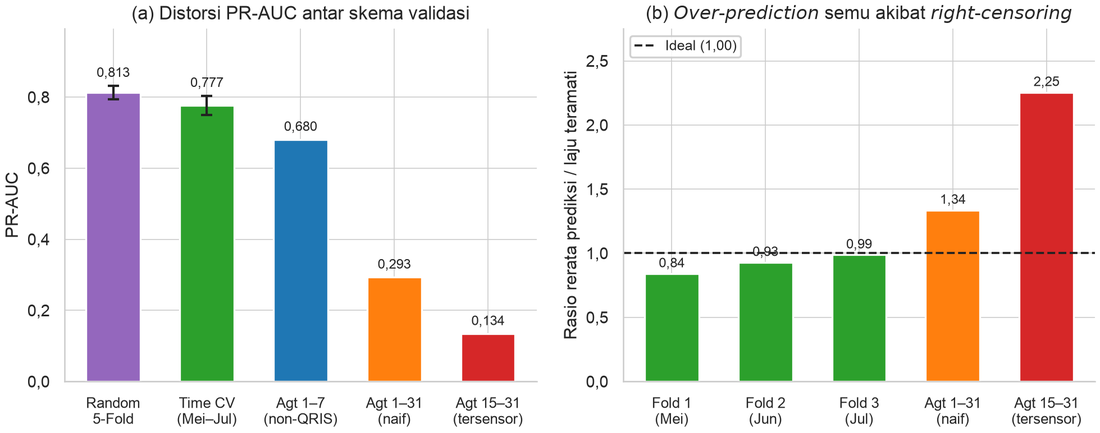

In [6]:
validasi = baca_hasil("task2_validation.json")
kolom = [
    "mean_pr_auc", "std_pr_auc", "mean_roc_auc", "std_roc_auc",
    "mean_cost_per_10k_tx_idr", "mean_ratio_pred_to_obs",
]
display(Markdown("**Time CV matang vs random CV**"))
display(tabel_metrik({
    "Time CV matang (3 fold)": validasi["time_cv_matang"],
    "Stratified random 5-fold": validasi["random_cv_matang"],
}, kolom))
display(Markdown("**Evaluasi pada Agustus yang tersensor**"))
display(tabel_metrik(validasi["validasi_agustus_tersensor"], [
    "n_val", "n_val_fraud", "obs_rate_pct", "pr_auc", "roc_auc", "ratio_pred_to_obs",
]))
display(pd.Series(validasi["ringkasan_selisih"], name="nilai", dtype=object).to_frame())
tampilkan_gambar("task2_2b_validation_comparison.png")

## 2c. Fitur Perilaku Kausal Pengguna dan *Merchant*

*Penanggung jawab: Rainaldi Pakpahan*

Semua fitur riwayat dihitung dari aliran transaksi yang diurutkan menurut waktu, dengan jaminan
hanya memakai transaksi sebelumnya (`t_past < t_now`):

- **Fitur perilaku tanpa label:** frekuensi, nominal, dan kebaruan transaksi per pengguna dan per
  *merchant* (pencarian biner tervektorisasi dengan `np.searchsorted`).
- **Fitur risiko historis berbasis label:** hanya memakai label yang sudah berumur ≥ 25 hari, agar
  konsisten dengan jeda konfirmasi pada validasi maupun data uji.

Ablasi bertahap menentukan himpunan fitur akhir.

In [7]:
%run ../src/klasifikasi/features.py --run-ablation

[START] Muat data & verifikasi kausalitas ketat (Tugas 2c)


  Verifikasi kausalitas LULUS: mutasi masa depan mengubah fitur masa lalu sebesar 0,0.


[DONE]  Muat data & verifikasi kausalitas ketat (Tugas 2c) (3.63s)
[START] 2c Ablasi: dasar (43 fitur)


  PR-AUC matang=0.7767 ± 0.0274 | Biaya/10k=7,208,807 Rp | QRIS Agt=0.5751
[DONE]  2c Ablasi: dasar (43 fitur) (22.29s)
[START] 2c Ablasi: plus_domain (59 fitur)


  PR-AUC matang=0.7810 ± 0.0323 | Biaya/10k=7,203,261 Rp | QRIS Agt=0.5921
[DONE]  2c Ablasi: plus_domain (59 fitur) (32.15s)
[START] 2c Ablasi: plus_user (72 fitur)


  PR-AUC matang=0.7845 ± 0.0278 | Biaya/10k=7,433,116 Rp | QRIS Agt=0.6129
[DONE]  2c Ablasi: plus_user (72 fitur) (25.73s)
[START] 2c Ablasi: plus_merchant (90 fitur)


  PR-AUC matang=0.8056 ± 0.0289 | Biaya/10k=6,101,238 Rp | QRIS Agt=0.6160
[DONE]  2c Ablasi: plus_merchant (90 fitur) (28.57s)
[START] 2c Ablasi: lengkap_2c (94 fitur)


  PR-AUC matang=0.8069 ± 0.0284 | Biaya/10k=6,189,499 Rp | QRIS Agt=0.5661
[DONE]  2c Ablasi: lengkap_2c (94 fitur) (39.04s)


[SAVED] task2_features.json


**Ablasi bertahap kelompok fitur (Time CV matang)**

,mean_cost_per_10k_idr,mean_pr_auc,mean_roc_auc,n_features,qris_shift_pr_auc,std_pr_auc
tahap,,,,,,
dasar,7.2088e+06,0.7767,0.9863,43,0.5751,0.0274
plus_domain,7.2033e+06,0.7810,0.9856,59,0.5921,0.0323
plus_user,7.4331e+06,0.7845,0.9862,72,0.6129,0.0278
plus_merchant,6.1012e+06,0.8056,0.9905,90,0.6160,0.0289
lengkap_2c,6.1895e+06,0.8069,0.9911,94,0.5661,0.0284


Tahap terpilih: plus_merchant (90 fitur)
Alasan: Himpunan 90 fitur kausal bebas-label (plus_merchant) memberi biaya terendah dan PR-AUC tertinggi pada gelombang QRIS baru, sekaligus kebal terhadap jeda konfirmasi label pada merchant baru di data uji Sep–Okt.


**15 fitur perilaku dengan *gain* terbesar**

,fitur,gain_ribu
0,ato_risk_sum,35.0577
1,user_burst_1j_vs_7h,23.8500
2,collusive_risk_score,13.8082
3,refund_x_umur_merchant_inv,11.5624
4,merch_tx_30d,8.8079
5,merch_tx_7d,8.0627
6,merch_past_tx_count,3.7690
7,qris_x_log_nominal,2.2354
8,merch_nominal_vs_merch_mean,2.1986
9,log_menit_sejak_trx,2.1100


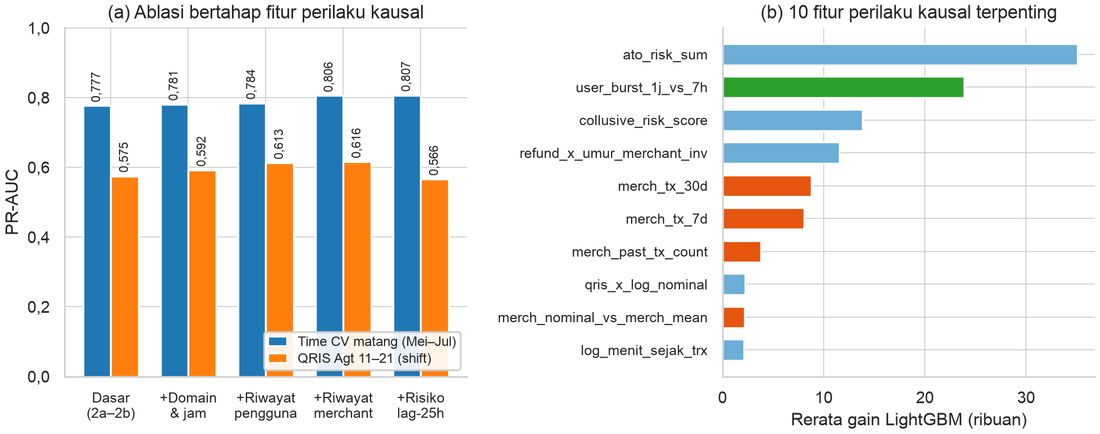

In [8]:
fitur = baca_hasil("task2_features.json")
display(Markdown("**Ablasi bertahap kelompok fitur (Time CV matang)**"))
display(pd.DataFrame(fitur["ablasi"]).set_index("tahap"))
print(f"Tahap terpilih: {fitur['tahap_terpilih']} ({fitur['jumlah_fitur_terpilih']} fitur)")
print("Alasan:", fitur["alasan_pemilihan"])
display(Markdown("**15 fitur perilaku dengan *gain* terbesar**"))
display(pd.DataFrame(fitur["top_fitur_perilaku"]))
tampilkan_gambar("task2_2c_behavioral_features.png")

## 2d. Penanganan *Class Imbalance* dan Perbandingan Model

*Penanggung jawab: Rainaldi Pakpahan*

Semua eksperimen berjalan di dalam Time CV matang 2b dengan fitur 2c.

1. **Pendekatan *imbalance*** (pada LightGBM yang identik): prior alami, *class weighting*,
   *random undersampling* 1:10, SMOTE 1:10, *threshold tuning* F1, dan aturan Bayes berbasis biaya
   (`prob × nominal > 25.000`).
2. **Keluarga model:** *logistic regression* (*baseline*), LightGBM, CatBoost, XGBoost, dan *ensemble*
   *log-odds* berbobot.

In [9]:
%run ../src/klasifikasi/models.py

[START] Muat data & bangun fitur kausal 2c


[DONE]  Muat data & bangun fitur kausal 2c (3.86s)
[START] 2d.1 Perbandingan pendekatan class imbalance


  natural_ambang_05         : PR-AUC=0.8036, F1=0.7811, Brier=0.00213, Biaya/10k=13,643,913
  class_weighting_05        : PR-AUC=0.7952, F1=0.6358, Brier=0.00449, Biaya/10k=8,831,476
  class_weighting_bayes_raw : PR-AUC=0.7952, F1=0.2967, Brier=0.00449, Biaya/10k=8,691,412
  random_undersampling_1_10 : PR-AUC=0.7820, F1=0.6364, Brier=0.00489, Biaya/10k=7,772,656
  smote_oversampling_1_10   : PR-AUC=0.7972, F1=0.7871, Brier=0.00213, Biaya/10k=12,339,213
  threshold_tuning_f1       : PR-AUC=0.8036, F1=0.7951, Brier=0.00213, Biaya/10k=10,603,342
  cost_sensitive_bayes      : PR-AUC=0.8036, F1=0.5619, Brier=0.00213, Biaya/10k=6,355,882
[DONE]  2d.1 Perbandingan pendekatan class imbalance (95.06s)
[START] 2d.2 Baseline Logistic Regression (tuning C)


  LogReg (C=0.05): PR-AUC=0.6855, Biaya/10k=9,463,160
[DONE]  2d.2 Baseline Logistic Regression (tuning C) (30.47s)
[START] 2d.3 LightGBM (tuning dalam 3-Fold Time CV)


  LightGBM terbaik: PR-AUC=0.8080, Biaya/10k=5,864,297
[DONE]  2d.3 LightGBM (tuning dalam 3-Fold Time CV) (106.32s)
[START] 2d.4 CatBoost (tuning dalam 3-Fold Time CV)


  CatBoost terbaik: PR-AUC=0.8009, Biaya/10k=6,451,529
[DONE]  2d.4 CatBoost (tuning dalam 3-Fold Time CV) (353.65s)
[START] 2d.5 XGBoost (tuning dalam 3-Fold Time CV)


  XGBoost terbaik : PR-AUC=0.8029, Biaya/10k=6,337,493
[DONE]  2d.5 XGBoost (tuning dalam 3-Fold Time CV) (47.12s)


  Ensemble Blend  : PR-AUC=0.8134 (F3 OOS=0.8152), Biaya/10k=6,039,213 | bobot={'lgbm': 0.6464911682487486, 'catboost': 0.23865225986528354, 'xgboost': 0.11485657188596787}


[SAVED] task2_models.json & cache/task2_oof.npz


**Perbandingan pendekatan class imbalance**

,mean_pr_auc,std_pr_auc,mean_roc_auc,mean_recall,mean_flag_rate_pct,total_cost_3fold_idr
cost_sensitive_bayes,0.8036,0.0292,0.9905,0.6870,0.9365,9.8604e+07
random_undersampling_1_10,0.7820,0.0229,0.9896,0.8054,0.9931,1.2078e+08
class_weighting_bayes_raw,0.7952,0.0262,0.9903,0.7866,2.7984,1.3482e+08
class_weighting_05,0.7952,0.0262,0.9903,0.8044,0.9916,1.3672e+08
threshold_tuning_f1,0.8036,0.0292,0.9905,0.7284,0.5394,1.6441e+08
smote_oversampling_1_10,0.7972,0.0302,0.9884,0.6790,0.4703,1.9151e+08
natural_ambang_05,0.8036,0.0292,0.9905,0.6705,0.4639,2.1140e+08


**Perbandingan keluarga model**

,mean_pr_auc,std_pr_auc,mean_roc_auc,mean_recall,mean_flag_rate_pct,total_cost_3fold_idr
lgbm,0.8080,0.0259,0.9909,0.7023,1.0484,9.1017e+07
ensemble,0.8134,0.0239,0.9907,0.7010,1.0037,9.3690e+07
xgboost,0.8029,0.0230,0.9905,0.6961,1.1717,9.8309e+07
catboost,0.8009,0.0222,0.9881,0.6900,0.9698,1.0007e+08
logreg,0.6855,0.0225,0.9748,0.6147,1.2711,1.4703e+08


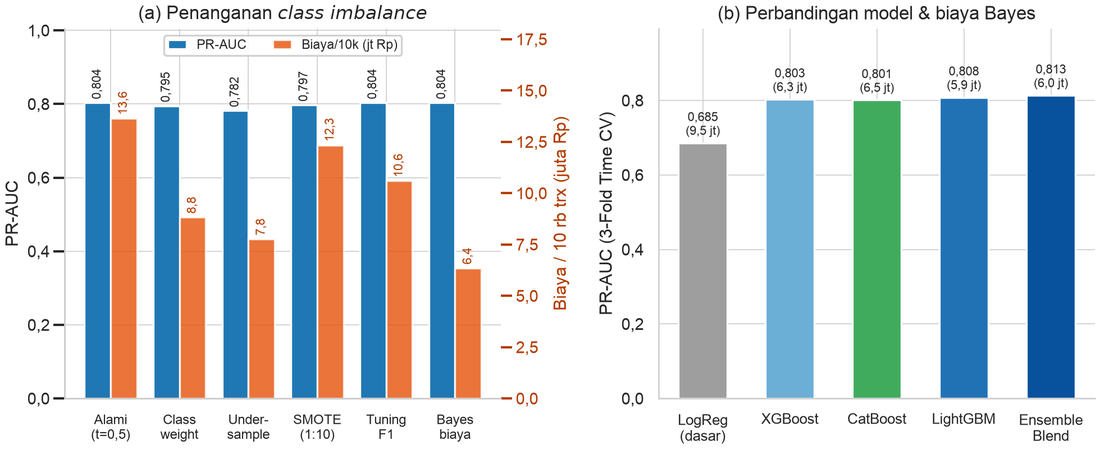

In [10]:
model = baca_hasil("task2_models.json")
kolom = [
    "mean_pr_auc", "std_pr_auc", "mean_roc_auc", "mean_recall",
    "mean_flag_rate_pct", "total_cost_3fold_idr",
]
display(Markdown("**Perbandingan pendekatan class imbalance**"))
display(tabel_metrik(model["imbalance_comparison"], kolom).sort_values("total_cost_3fold_idr"))
display(Markdown("**Perbandingan keluarga model**"))
display(tabel_metrik(model["model_comparison"], kolom).sort_values("total_cost_3fold_idr"))
tampilkan_gambar("task2_2d_imbalance_and_models.png")

## 2e. Pergeseran Pola *Fraud* dan Adaptasi Model

*Penanggung jawab: Rainaldi Pakpahan*

Gelombang *fraud* QRIS bernominal bulat muncul mulai 1 Agustus 2025. Enam strategi adaptasi
dibandingkan secara kronologis: latih sampai 10 Agustus, evaluasi pada 11–21 Agustus (ekor 22–31
Agustus yang labelnya paling tersensor dibuang). Strategi mencakup tanpa adaptasi, menambah data awal
Agustus dengan bobot 1×, 3×, 6×, 10×, serta peluruhan waktu.

In [11]:
%run ../src/klasifikasi/shift.py

[START] Muat data & fitur kausal 2c untuk eksperimen shift 2e


[DONE]  Muat data & fitur kausal 2c untuk eksperimen shift 2e (3.44s)


[START] 2e Evaluasi strategi: tanpa_adaptasi_jan_jul


  Overall PR-AUC=0.2525 | QRIS PR-AUC=0.1749 (rec=22.5%) | Non-QRIS PR-AUC=0.3809 | Cost=43.03M Rp
[DONE]  2e Evaluasi strategi: tanpa_adaptasi_jan_jul (11.64s)
[START] 2e Evaluasi strategi: tambah_agt_awal_1x


  Overall PR-AUC=0.4292 | QRIS PR-AUC=0.5989 (rec=87.5%) | Non-QRIS PR-AUC=0.4009 | Cost=9.74M Rp
[DONE]  2e Evaluasi strategi: tambah_agt_awal_1x (11.74s)
[START] 2e Evaluasi strategi: recency_3x


  Overall PR-AUC=0.4690 | QRIS PR-AUC=0.6355 (rec=90.0%) | Non-QRIS PR-AUC=0.4152 | Cost=9.00M Rp
[DONE]  2e Evaluasi strategi: recency_3x (11.57s)
[START] 2e Evaluasi strategi: recency_6x


  Overall PR-AUC=0.4672 | QRIS PR-AUC=0.5981 (rec=87.5%) | Non-QRIS PR-AUC=0.4172 | Cost=9.39M Rp
[DONE]  2e Evaluasi strategi: recency_6x (11.34s)
[START] 2e Evaluasi strategi: recency_10x


  Overall PR-AUC=0.4560 | QRIS PR-AUC=0.5998 (rec=87.5%) | Non-QRIS PR-AUC=0.3950 | Cost=10.55M Rp
[DONE]  2e Evaluasi strategi: recency_10x (11.77s)
[START] 2e Evaluasi strategi: decay_dan_recency_6x


  Overall PR-AUC=0.4670 | QRIS PR-AUC=0.6119 (rec=87.5%) | Non-QRIS PR-AUC=0.4059 | Cost=10.10M Rp
[DONE]  2e Evaluasi strategi: decay_dan_recency_6x (11.65s)


[SAVED] task2_shift.json


,w_recent,decay_half_life_days,overall_pr_auc,qris_pr_auc,qris_recall,non_qris_pr_auc,overall_cost_idr
strategi,,,,,,,
tanpa_adaptasi_jan_jul,0.0,NaN,0.2525,0.1749,0.225,0.3809,4.3031e+07
tambah_agt_awal_1x,1.0,NaN,0.4292,0.5989,0.875,0.4009,9.7367e+06
recency_3x,3.0,NaN,0.4690,0.6355,0.900,0.4152,8.9957e+06
recency_6x,6.0,NaN,0.4672,0.5981,0.875,0.4172,9.3867e+06
recency_10x,10.0,NaN,0.4560,0.5998,0.875,0.3950,1.0546e+07
decay_dan_recency_6x,6.0,180.0,0.4670,0.6119,0.875,0.4059,1.0103e+07


,strategi terpilih
decay_half_life_days,None
nama,recency_3x
overall_cost_idr,8995700.0
overall_pr_auc,0.469
penghematan_vs_tanpa_adaptasi_idr,34035200.0
qris_pr_auc,0.6355
qris_recall,0.9
w_recent,3.0


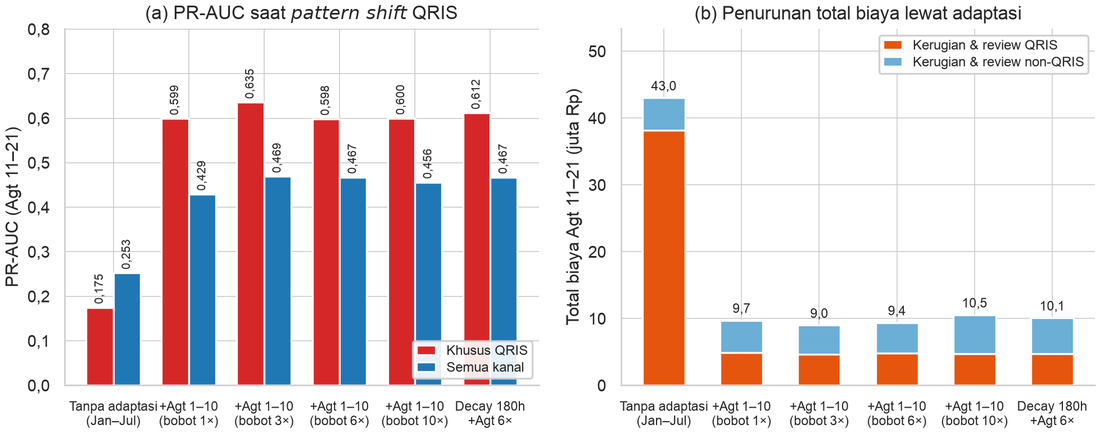

In [12]:
shift = baca_hasil("task2_shift.json")
kolom = [
    "w_recent", "decay_half_life_days", "overall_pr_auc", "qris_pr_auc",
    "qris_recall", "non_qris_pr_auc", "overall_cost_idr",
]
display(pd.DataFrame(shift["strategi"]).set_index("strategi")[kolom])
display(pd.Series(shift["strategi_terpilih"], name="strategi terpilih", dtype=object).to_frame())
tampilkan_gambar("task2_2e_pattern_shift_adaptation.png")